# 12 — Tickets, Chat Logs and the SQLite Store

## 1. Introduction and objectives

This notebook (Phase 1F) completes the *Order & ticket logs* box of the data layer. Phase 1E
produced **contacts** (who wrote, when, about what). A contact center also keeps:

- a **ticket** per case: what the advisor found, what was decided, whether work remains,
  when the case was resolved, and how satisfied the customer was;
- the **chat log**: the messages exchanged.

Both are generated by real code in `src/callverse/data/` (`tickets.py`, `conversations.py`,
tested in `tests/unit/test_tickets.py`) and stored, with the Olist tables, in one SQLite file
(`database.py`, `tests/unit/test_database.py`). `scripts/build_database.py` rebuilds everything
in one command. This notebook checks and describes the result.

**Decisions (agreed for version 1)**

| Topic | Decision |
|---|---|
| Ticket grain | One ticket per contact; repeat contacts on an order stay linkable by `order_id` |
| Channel | Chat for every contact |
| Chat method | Templates filled with the order facts at contact time and the knowledge-base policy |
| Outcome | Rules from the order facts at contact time (no future information) |
| Handle time | Same lognormal per intent group as `configs/simulation.yaml` |
| Random parts | Supervisor requests and the satisfaction survey, with assumed rates (`configs/data.yaml`) |

> Everything in the tickets and chats is **synthetic**. Olist has no support data; the
> rules and rates are explicit, adjustable assumptions.

## 2. Imports, paths and inputs

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from callverse.data import (
    ORDER_COLUMNS,
    build_database,
    connect,
    generate_chat_messages,
    generate_tickets,
    load_ticket_config,
)
from callverse.simulation import load_simulation_config

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
KB_DOCS = PROJECT_ROOT / "data" / "knowledge_base" / "docs"
DATA_CONFIG = PROJECT_ROOT / "configs" / "data.yaml"
SIMULATION_CONFIG = PROJECT_ROOT / "configs" / "simulation.yaml"

required_files = [PROCESSED_DIR / f"{name}.parquet" for name in [
    "synthetic_contacts", "olist_orders_analytical", "olist_customers_prepared",
    "olist_sellers_prepared", "olist_products_prepared", "olist_order_items_prepared",
    "olist_payments_prepared"]]
missing = [str(p) for p in required_files if not p.exists()]
assert not missing, f"Missing inputs (run notebooks 03 to 08): {missing}"

ticket_config = load_ticket_config(DATA_CONFIG)
with open(DATA_CONFIG, encoding="utf-8") as config_file:
    DB_PATH = PROJECT_ROOT / yaml.safe_load(config_file)["database"]["path"]
simulation = load_simulation_config(SIMULATION_CONFIG)
service_times = {g: (s.mean_seconds, s.cv) for g, s in simulation.service_times.items()}

contacts = pd.read_parquet(PROCESSED_DIR / "synthetic_contacts.parquet")
orders = pd.read_parquet(PROCESSED_DIR / "olist_orders_analytical.parquet")
print(f"{len(contacts):,} contacts, {len(orders):,} orders, seed {ticket_config.random_seed}")

9,179 contacts, 99,441 orders, seed 42


## 3. Generate tickets and chats

`generate_tickets` works in five steps:

1. **Status at contact time**, from the Olist timestamps: created, approved, shipped,
   delivered, or canceled/unavailable. The final `order_status` is *not* used, because it
   is only known in hindsight.
2. **Outcome** by rules that follow the knowledge-base policies. For example, a parcel past
   its estimated date that is more than 7 days late *or* more than 25 days in transit (the
   95th percentile of Olist transit times) gets a carrier investigation.
3. **Supervisor request**: random, 1% of cases resolved in the chat, 6% of those with
   follow-up work.
4. **Handle time** from the simulation's lognormal; **resolution time** = end of chat + the
   follow-up business days of the outcome.
5. **Satisfaction survey**: 30% answer; the score depends on the outcome class.

In [2]:
tickets = generate_tickets(contacts, orders, ticket_config, service_times)
messages = generate_chat_messages(tickets, contacts, orders, ticket_config.random_seed)
print(f"{len(tickets):,} tickets, {len(messages):,} chat messages")

again = generate_tickets(contacts, orders, ticket_config, service_times)
assert tickets.equals(again), "Tickets are not reproducible"
print("Same seed gives identical tickets:", tickets.equals(again))
tickets.head(3).T

9,179 tickets, 60,837 chat messages


Same seed gives identical tickets: True


,0,1,2
ticket_id,TK000001,TK000002,TK000003
contact_id,SC000001,SC000002,SC000003
order_id,ca5a215980675471f0cf8199c041909a,2e2e88c4bb691287b71a9e1ee8a193a4,76774c936de5cb5a431120fde98e40da
customer_unique_id,12f5d6e1cbf93dafd9dcc19095df0b3d,ee3f102da1f94d5782046090f5c6c67c,6d9e2c0d8e12764c96436cdd2cd11655
channel,chat,chat,chat
intent,delivery_time,change_order,delivery_time
intent_group,wismo,order_admin,wismo
opened_at,2017-01-11 14:26:47,2017-01-13 17:44:20,2017-01-14 00:47:28
order_status_at_contact,approved,created,approved
days_past_estimate,-21,-40,-33


## 4. Consistency checks

In [3]:
checks = {}
checks["one ticket per contact"] = tickets.contact_id.is_unique and len(tickets) == len(contacts)
checks["chat ends after it starts"] = (tickets.chat_closed_at > tickets.opened_at).all()
checks["resolved after the chat"] = (tickets.resolved_at >= tickets.chat_closed_at).all()
checks["contact after purchase"] = (
    tickets.opened_at >= tickets.merge(orders, on="order_id").order_purchase_timestamp).all()

first = messages.groupby("ticket_id").first()
last = messages.groupby("ticket_id").last()
by_ticket = tickets.set_index("ticket_id")
checks["chat opens with the customer message"] = (
    first.text == by_ticket.contact_id.map(contacts.set_index("contact_id").message_text)
).all()
checks["first message at opened_at"] = (first.sent_at == by_ticket.opened_at).all()
checks["last message at chat_closed_at"] = (last.sent_at == by_ticket.chat_closed_at).all()
checks["messages in time order"] = messages.groupby("ticket_id").sent_at.apply(
    lambda s: s.is_monotonic_increasing).all()
checks["answer cites the ticket's KB section"] = messages.merge(
    tickets[["ticket_id", "kb_chunk_id"]], on=["ticket_id", "kb_chunk_id"]
).ticket_id.nunique() == len(tickets)

from callverse.agents.advisor import load_chunks  # notebook only: data code does not import agents
kb_ids = {c.chunk_id for c in load_chunks(KB_DOCS, 1500)}
checks["every cited KB section exists"] = set(messages.kb_chunk_id.dropna()) <= kb_ids

pd.Series(checks, name="passed").to_frame()

,passed
one ticket per contact,True
chat ends after it starts,True
resolved after the chat,True
contact after purchase,True
chat opens with the customer message,True
first message at opened_at,True
last message at chat_closed_at,True
messages in time order,True
answer cites the ticket's KB section,True
every cited KB section exists,True


In [4]:
assert all(checks.values()), [name for name, ok in checks.items() if not ok]

handle = tickets.groupby("intent_group").handle_seconds.agg(["mean", "std"])
handle["config_mean"] = handle.index.map(lambda g: service_times[g][0])
handle["config_cv"] = handle.index.map(lambda g: service_times[g][1])
handle["observed_cv"] = handle["std"] / handle["mean"]
handle.round(2)

,mean,std,config_mean,config_cv,observed_cv
intent_group,,,,,
cancel_refund,368.37,256.16,360.0,0.6,0.70
order_admin,241.62,153.33,240.0,0.6,0.63
post_delivery,423.14,248.39,420.0,0.6,0.59
wismo,180.23,107.47,180.0,0.6,0.60


The observed mean and coefficient of variation of handle times match the simulation's
assumptions, so the tickets and the simulated queue describe the same contact center.

## 5. What happened in the tickets

In [5]:
status_mix = pd.crosstab(tickets.intent_group, tickets.order_status_at_contact)
status_mix

order_status_at_contact,approved,canceled,created,delivered,shipped,unavailable
intent_group,,,,,,
cancel_refund,0,289,0,0,0,308
order_admin,527,2,164,142,254,2
post_delivery,0,0,0,2718,0,0
wismo,651,0,2,0,4120,0


In [6]:
outcome_table = (tickets.groupby(["outcome", "outcome_class"]).size()
                 .rename("tickets").reset_index().sort_values("tickets", ascending=False))
outcome_table["share"] = (outcome_table.tickets / len(tickets)).round(3)
outcome_table

,outcome,outcome_class,tickets,share
8,delay_acknowledged,resolved_in_chat,2006,0.219
31,tracking_shared,resolved_in_chat,1268,0.138
23,return_label_sent,follow_up,1202,0.131
6,carrier_investigation,follow_up,765,0.083
21,replacement_or_refund_offered,follow_up,736,0.080
27,seller_contacted,follow_up,605,0.066
3,cancel_and_reorder_advised,resolved_in_chat,502,0.055
11,exchange_started,follow_up,385,0.042
16,invoice_sent,resolved_in_chat,373,0.041
19,refund_timing_given,resolved_in_chat,349,0.038


In [7]:
kpis = pd.DataFrame({
    "first_contact_resolution": tickets.groupby("intent_group").first_contact_resolution.mean(),
    "escalated": tickets.groupby("intent_group").outcome_class.apply(lambda s: s.eq("escalated").mean()),
    "mean_days_to_resolve": tickets.assign(
        days=(tickets.resolved_at - tickets.opened_at).dt.total_seconds() / 86400
    ).groupby("intent_group").days.mean(),
    "csat_mean": tickets.groupby("intent_group").csat_score.mean(),
    "csat_answered": tickets.groupby("intent_group").csat_score.count(),
})
total = pd.DataFrame({
    "first_contact_resolution": [tickets.first_contact_resolution.mean()],
    "escalated": [tickets.outcome_class.eq("escalated").mean()],
    "mean_days_to_resolve": [((tickets.resolved_at - tickets.opened_at).dt.total_seconds() / 86400).mean()],
    "csat_mean": [tickets.csat_score.mean()],
    "csat_answered": [tickets.csat_score.count()],
}, index=["all"])
pd.concat([kpis, total]).round(3)

,first_contact_resolution,escalated,mean_days_to_resolve,csat_mean,csat_answered
cancel_refund,0.863,0.017,1.884,4.152,178
order_admin,0.987,0.013,0.030,4.236,309
post_delivery,0.009,0.056,13.376,3.625,801
wismo,0.688,0.025,1.606,4.008,1425
all,0.534,0.032,4.922,3.93,2713


**Reading the KPIs.** First-contact resolution is defined strictly: a ticket counts only when
nothing is left to do at the end of the chat. A sent return label or an opened carrier
investigation therefore counts as *not* resolved at first contact, which explains the low
value for post-delivery problems. The mean satisfaction (about 4 out of 5) is in line with the
directional chat benchmark used in the config (80 to 85% "satisfied").

### 5.1 Outcomes by hidden cause

`generator_situation` is the hidden reason each contact was generated. It is **not** used by
the rules (and not stored in SQLite); here it only checks that the rules react sensibly.

In [8]:
by_situation = pd.crosstab(
    tickets.merge(contacts[["contact_id", "generator_situation"]], on="contact_id").generator_situation,
    tickets.outcome, normalize="index")
top_outcomes = tickets.outcome.value_counts().index[:8]
by_situation[top_outcomes].round(2)

outcome,delay_acknowledged,tracking_shared,return_label_sent,carrier_investigation,replacement_or_refund_offered,seller_contacted,cancel_and_reorder_advised,exchange_started
generator_situation,,,,,,,,
canceled_or_unavailable,0.00,0.0,0.00,0.00,0.00,0.00,0.0,0.00
change_before_shipping,0.00,0.0,0.00,0.00,0.00,0.00,1.0,0.00
delivered_late,0.74,0.0,0.00,0.22,0.00,0.04,0.0,0.00
invoice_request,0.00,0.0,0.00,0.00,0.00,0.00,0.0,0.00
on_time_tracking_check,0.00,1.0,0.00,0.00,0.00,0.00,0.0,0.00
overdue_never_delivered,0.34,0.0,0.00,0.31,0.00,0.36,0.0,0.00
payment_anomaly,0.00,0.0,0.00,0.00,0.00,0.00,0.0,0.00
post_delivery_problem,0.00,0.0,0.47,0.00,0.29,0.00,0.0,0.15
seller_shipped_late,0.00,0.0,0.00,0.00,0.00,1.00,0.0,0.00


Orders that were never delivered get the most carrier investigations, while on-time tracking
checks are answered with the tracking information: the rules follow the cause without seeing
it. About one third of investigations end early because the parcel is delivered in the
meantime.

In [9]:
investigations = tickets[tickets.outcome == "carrier_investigation"].merge(
    orders[["order_id", "order_delivered_customer_date"]], on="order_id")
ended_by_delivery = investigations.resolved_at.eq(investigations.order_delivered_customer_date)
print(f"{len(investigations)} investigations; {ended_by_delivery.mean():.0%} ended by delivery")

813 investigations; 35% ended by delivery


## 6. Chat logs

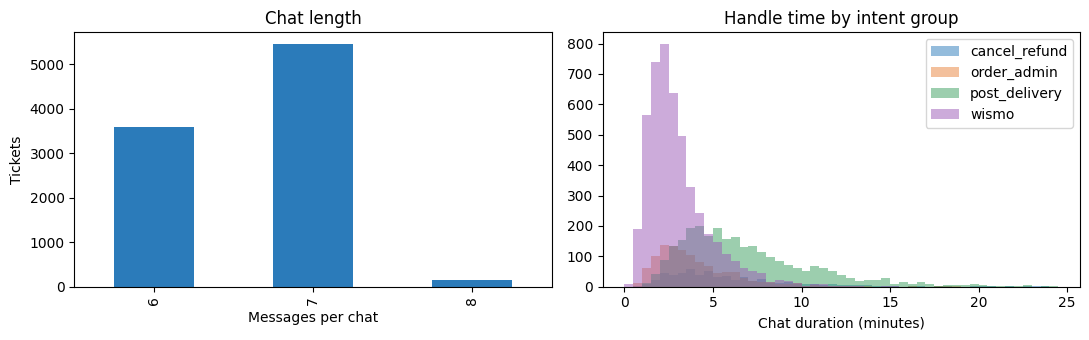

speaker
customer    33009
advisor     27828


In [10]:
chat_length = messages.groupby("ticket_id").size()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
chat_length.value_counts().sort_index().plot.bar(ax=axes[0], color="#2b7bba")
axes[0].set_xlabel("Messages per chat")
axes[0].set_ylabel("Tickets")
axes[0].set_title("Chat length")
for group, color in zip(sorted(service_times), ["#2b7bba", "#e8833a", "#3a9e5f", "#9b59b6"]):
    minutes = tickets.loc[tickets.intent_group == group, "handle_seconds"] / 60
    axes[1].hist(minutes, bins=np.arange(0, 25, 0.5), alpha=0.5, label=group, color=color)
axes[1].set_xlabel("Chat duration (minutes)")
axes[1].set_title("Handle time by intent group")
axes[1].legend()
plt.tight_layout()
plt.show()
print(messages.speaker.value_counts().to_string())

In [11]:
def show_chat(ticket_id):
    ticket = tickets.set_index("ticket_id").loc[ticket_id]
    print(f"{ticket_id} | {ticket.intent} | status {ticket.order_status_at_contact} | "
          f"outcome {ticket.outcome} | handled in {ticket.handle_seconds // 60} min")
    for m in messages[messages.ticket_id == ticket_id].itertuples():
        source = f"   [{m.kb_chunk_id}]" if m.kb_chunk_id else ""
        print(f"  {m.sent_at:%H:%M:%S} {m.speaker:>8}: {m.text}{source}")
    print()


rng = np.random.default_rng(ticket_config.random_seed)
for outcome in ["delay_acknowledged", "carrier_investigation", "return_label_sent",
                "bank_details_requested"]:
    show_chat(rng.choice(tickets.loc[tickets.outcome == outcome, "ticket_id"]))
show_chat(rng.choice(tickets.loc[tickets.supervisor_requested, "ticket_id"]))

TK001363 | track_delivery | status shipped | outcome delay_acknowledged | handled in 2 min
  10:22:44 customer: I would like to track my package, how to do it?
  10:23:17  advisor: Hi! Thanks for reaching out, I'll look into this for you. First, may I have your order number and the e-mail linked to your account?   [advisor_playbook__s01]
  10:23:44 customer: Sure, the order number is 9feb8a417a078949bf56e26f46bae06d and the e-mail is the one I'm writing from.
  10:24:33  advisor: I'm sorry: your order is still with the carrier and the estimated date (18 July 2017) passed 1 day ago. The parcel is still moving, so please allow 3 more business days. If it has not arrived by then, contact us and we will open an investigation with the carrier.   [delivery_times_and_delays__s03]
  10:24:41 customer: Perfect, thanks for your help.
  10:25:05  advisor: So, your parcel is late but still moving; please allow 3 more business days. Can I help you with anything else today?   [advisor_playbook__s05]

**Known limit.** The customer's first message is the Bitext message chosen in Phase 1E. A few
Bitext messages fit their intent label loosely (for example a `track_order` message asking
about a *replacement*), so the advisor's answer can look slightly off-topic. Later turns are
fixed templates and use little vocabulary; they are meant for testing tools and rules, not
for training a language model.

## 7. SQLite store

The store keeps the Olist tables an advisor needs (customers, orders, items, payments,
products, sellers) and the synthetic support tables (contacts, tickets, chat messages), with
primary keys, foreign keys and indexes. `generator_*` columns of contacts are **left out**,
so agents querying the store cannot see the hidden cause of a contact.

In [12]:
contact_columns = [c for c in contacts.columns if not c.startswith("generator_")]
read = lambda name: pd.read_parquet(PROCESSED_DIR / f"{name}.parquet")
counts = build_database({
    "customers": read("olist_customers_prepared"),
    "sellers": read("olist_sellers_prepared"),
    "products": read("olist_products_prepared"),
    "orders": orders[ORDER_COLUMNS],
    "order_items": read("olist_order_items_prepared"),
    "payments": read("olist_payments_prepared"),
    "contacts": contacts[contact_columns],
    "tickets": tickets,
    "chat_messages": messages,
}, DB_PATH)
tickets.to_parquet(PROCESSED_DIR / "synthetic_tickets.parquet", index=False)
messages.to_parquet(PROCESSED_DIR / "synthetic_chat_messages.parquet", index=False)
print(f"{DB_PATH.name}: {DB_PATH.stat().st_size / 1e6:.0f} MB, foreign-key check passed")
pd.Series(counts, name="rows").to_frame()

callverse.db: 129 MB, foreign-key check passed


,rows
customers,99441
sellers,3095
products,32951
orders,99441
order_items,112650
payments,103886
contacts,9179
tickets,9179
chat_messages,60837


Example queries an advisor tool will run. The store is opened **read-only**.

In [13]:
connection = connect(DB_PATH)
example_order = tickets.loc[tickets.outcome == "carrier_investigation", "order_id"].iloc[0]

order_lookup = pd.read_sql("""
    SELECT order_id, order_status, order_purchase_timestamp, order_estimated_delivery_date,
           primary_payment_type, order_value, distinct_sellers
    FROM orders WHERE order_id = ?""", connection, params=[example_order])
history = pd.read_sql("""
    SELECT t.ticket_id, t.opened_at, t.intent, t.outcome, t.resolved_at,
           COUNT(m.message_id) AS messages
    FROM tickets t JOIN chat_messages m USING (ticket_id)
    WHERE t.customer_unique_id = (SELECT customer_unique_id FROM orders WHERE order_id = ?)
    GROUP BY t.ticket_id ORDER BY t.opened_at""", connection, params=[example_order])
display(order_lookup.T)
display(history)

,0
order_id,acc3d4031cbd2f28ac6b5b71427a054c
order_status,delivered
order_purchase_timestamp,2017-01-09 21:40:42
order_estimated_delivery_date,2017-02-07 00:00:00
primary_payment_type,credit_card
order_value,130.75
distinct_sellers,1.0


,ticket_id,opened_at,intent,outcome,resolved_at,messages
0,TK000058,2017-02-09 11:24:45,track_order,carrier_investigation,2017-02-16 11:29:37,7


In [14]:
monthly = pd.read_sql("""
    SELECT substr(opened_at, 1, 7) AS month, COUNT(*) AS tickets,
           ROUND(AVG(first_contact_resolution), 3) AS fcr,
           ROUND(AVG(csat_score), 2) AS csat
    FROM tickets GROUP BY month ORDER BY month""", connection)
connection.close()
monthly.tail(8)

,month,tickets,fcr,csat
12,2018-01,679,0.399,3.89
13,2018-02,616,0.513,3.94
14,2018-03,963,0.597,3.97
15,2018-04,958,0.485,3.86
16,2018-05,613,0.476,3.78
17,2018-06,518,0.539,3.91
18,2018-07,375,0.568,3.91
19,2018-08,747,0.606,3.93


## 8. Conclusions

1. **9,179 tickets and 60,837 chat messages** (6 to 8 per chat) were generated, one ticket
   per contact, reproducibly (fixed seed). All 10 consistency checks pass: timelines,
   message order, and every cited knowledge-base section exists.
2. **Consistent with the rest of the twin.** Handle times reproduce the simulation's
   assumptions (means within 1%, CVs 0.59 to 0.70), and every advisor answer cites the
   policy section it applies.
3. **Outcomes follow the hidden cause without seeing it.** On-time tracking checks all get
   the tracking information; seller-late orders all lead to the seller being contacted;
   never-delivered orders get the most investigations (31%), and 35% of investigations end
   early because the parcel arrives.
4. **KPIs (synthetic).** Strict first-contact resolution 53% (99% for order administration,
   1% for post-delivery problems, which always need a return or a check), 3.2% escalated,
   4.9 days to resolve on average, mean satisfaction 3.93 / 5 (2,713 answers).
5. **SQLite store** (129 MB): 9 tables with primary keys, foreign keys (check passed) and
   indexes; read-only access for agents; the hidden cause of each contact is not stored.

**Points for the advisor phase**

- The `orders` table holds the **final** status and all timestamps. An advisor tool must
  rebuild the status *as of the chat time* (as `order_status_at` does), or it would see the
  future.
- Chats are templates: good for testing tools, retrieval and the quality rubric, not for
  training a language model. A small LLM-written set can be added later if needed.